# RFM & Behavioral Customer Segmentation
**Joseph Ikogho · Data Science Portfolio Project 2**

Goal: replace generic campaigns with understandable customer groups and testable, differentiated engagement plans. Public UCI Online Retail transaction data. No campaign uplift is measured. Designed by Nova Agentic.

## 1. Data provenance and decision framework
Source: Chen, D. (2015), Online Retail, UCI dataset 352, DOI 10.24432/C5BW33, CC BY 4.0. Unlike Wholesale Customers, this dataset provides dated customer transactions needed for Recency and distinct-invoice Frequency. The original workbook is serialized as compressed CSV without dropping rows; a separate cleaning audit records exclusions. Some customers are wholesalers. Currency is GBP.

Workflow: manually calculate RFM and rule-based tiers first; log-transform and scale RFM; justify k with elbow diagnostics; profile clusters in original units; attach plain-English names and campaign hypotheses. Additional transaction behavior is a profiling lens, not a hidden clustering input.

In [1]:
from pathlib import Path
import os,sys,json
ROOT=Path.cwd() if (Path.cwd()/'src/segment.py').exists() else Path.cwd().parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Image
from src.features import clean_transactions,compute_rfm,fit_baseline,RFM
from src.segment import main
raw=pd.read_csv('data/online_retail.csv.gz',dtype={'InvoiceNo':'string','StockCode':'string'})
print('Raw shape:',raw.shape)
display(raw.head())
display(raw.isna().sum().to_frame('missing'))

Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,missing
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


## 2. Clean transactions and freeze the observation window
Reference date: day after the last recorded invoice, fixed at 2011-12-10. The 365-day window is [2010-12-10, 2011-12-10). Remove exact duplicates, invalid numeric/date fields, missing customer IDs, cancellations, nonpositive quantities and nonpositive prices. Future rows are excluded. Duplicate removal is an explicit assumption because identical rows cannot be distinguished from legitimate repeats without line IDs.

Monetary represents positive purchase value; returns and cancellations are excluded rather than netted. Missing-ID customers are omitted, creating selection bias. This is not profit, net revenue or lifetime value.

In [2]:
clean,audit,as_of=clean_transactions(raw)
display(audit)
print('As of:',as_of.date(),'Eligible lines:',len(clean))
print('Clean purchase value (£):',clean.LineRevenue.sum())

As of: 2011-12-10 Eligible lines: 378508
Clean purchase value (£): 8576552.524


,step,remaining,removed
0,Raw rows,541909,0
1,Remove exact duplicate lines,536641,5268
2,Remove invalid dates/amounts,536641,0
3,Remove missing/invalid customer IDs,401604,135037
4,Remove missing invoice/product IDs,401604,0
5,Exclude cancellation invoices,392732,8872
6,Exclude nonpositive quantities,392732,0
7,Exclude nonpositive prices,392692,40
8,Apply historical observation window,378508,14184


## 3. Manually calculate RFM in pandas before modeling
Recency = days since the latest purchase. Frequency = unique invoices, not line count or units. Monetary = sum of quantity × price. Features are computed per identified customer over the fixed window. Verify the reusable function against explicit pandas operations.

In [3]:
g=clean.groupby('CustomerID')
manual=pd.DataFrame({'Recency':(as_of-g.InvoiceDate.max().dt.normalize()).dt.days,'Frequency':g.InvoiceNo.nunique(),'Monetary':g.LineRevenue.sum()}).reset_index()
rfm=compute_rfm(clean,as_of)
pd.testing.assert_frame_equal(manual[['CustomerID']+RFM],rfm[['CustomerID']+RFM],check_dtype=False)
display(manual.head(10))
display(manual[RFM].describe())

,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,3,6,3598.21
2,12348,76,4,1797.24
3,12349,19,1,1757.55
4,12350,311,1,334.40
5,12352,37,8,2506.04
6,12353,205,1,89.00
7,12354,233,1,1079.40
8,12355,215,1,459.40
9,12356,23,3,2811.43


,Recency,Frequency,Monetary
count,4264.000000,4264.000000,4264.000000
mean,88.241792,4.164165,2011.386614
std,93.888162,7.394279,8780.849894
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,303.045000
50%,50.000000,2.000000,660.660000
75%,134.000000,5.000000,1636.362500
max,365.000000,193.000000,280206.020000


## 4. Build the intuitive RFM baseline
Population quintiles score each metric 1–5; smaller recency gets a larger score. Equal values retain equal scores using cutoffs and left-side insertion. Repeated Frequency values can yield unequal bucket sizes. Ordered, exhaustive rules create Champions, High value at risk of lapsing, Newly observed customers still exploring, Loyal repeat customers, Lapsed low-activity customers and Developing customers. “Newly observed” is window-relative, not first-ever membership.

In [4]:
baseline,cutoffs=fit_baseline(rfm)
print('Quintile cutoffs:',cutoffs)
display(baseline[['CustomerID','Recency','Frequency','Monetary','R_score','F_score','M_score','RFM_code','baseline_tier']].head(15))
display(baseline.baseline_tier.value_counts())

Quintile cutoffs: {'Recency': [13.0, 32.0, 69.0, 171.0], 'Frequency': [1.0, 2.0, 3.0, 5.0], 'Monetary': [243.68, 480.75, 924.8, 2024.7880000000005]}


,CustomerID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_code,baseline_tier
0,12346,326,1,77183.60,1,1,5,115,High value at risk of lapsing
1,12347,3,6,3598.21,5,5,5,555,Champions
2,12348,76,4,1797.24,2,4,4,244,High value at risk of lapsing
3,12349,19,1,1757.55,4,1,4,414,Newly observed customers still exploring
4,12350,311,1,334.40,1,1,2,112,Lapsed low-activity customers
5,12352,37,8,2506.04,3,5,5,355,Loyal repeat customers
6,12353,205,1,89.00,1,1,1,111,Lapsed low-activity customers
7,12354,233,1,1079.40,1,1,4,114,High value at risk of lapsing
8,12355,215,1,459.40,1,1,2,112,Lapsed low-activity customers
9,12356,23,3,2811.43,4,3,5,435,Loyal repeat customers


baseline_tier
Lapsed low-activity customers               1235
Champions                                    875
Developing customers                         719
Loyal repeat customers                       681
High value at risk of lapsing                411
Newly observed customers still exploring     343
Name: count, dtype: int64

## 5. Scale RFM, run K-Means and justify k
Log1p reduces skew without deleting large accounts. StandardScaler puts transformed inputs on comparable scales. K-Means uses only Recency, Frequency and Monetary, n_init=20 and seed 42. Evaluate k=1…10. The largest distance below the normalized endpoint chord provides a reproducible elbow candidate; it is a heuristic, not proof of an objectively true k. Silhouette, range sensitivity, seed stability and outlier sensitivity complement the elbow.

In [5]:
m=main()
display(pd.read_csv('outputs/elbow_diagnostics.csv'))
print('Selected k:',m['selected_k'])
print('Chosen-k sampled silhouette:',m['silhouette_sampled'])
print('Range 1–8 elbow:',m['elbow_k_range_1_to_8'])
print('Minimum seed ARI:',m['seed_ari_min'])
print('99%-capped alternative ARI:',m['capped_99pct_ari'])

{
  "raw_rows": 541909,
  "eligible_lines": 378508,
  "customers": 4264,
  "orders": 17756,
  "as_of": "2011-12-10",
  "window_start": "2010-12-10",
  "window_days": 365,
  "selected_k": 3,
  "silhouette_sampled": 0.34025801762110985,
  "gross_purchase_value_gbp": 8576552.524,
  "seed_ari_min": 0.9840123757789314,
  "capped_99pct_ari": 0.917189435469763,
  "elbow_k_range_1_to_8": 3,
  "baseline_tiers": 6,
  "baseline_cutoffs": {
    "Recency": [
      13.0,
      32.0,
      69.0,
      171.0
    ],
    "Frequency": [
      1.0,
      2.0,
      3.0,
      5.0
    ],
    "Monetary": [
      243.68,
      480.75,
      924.8,
      2024.7880000000005
    ]
  },
  "data_sha256": "04c43811f0568c19f1b10cde30ad87d4e832229202ae0994d29046d4cfd4d015"
}
Selected k: 3
Chosen-k sampled silhouette: 0.34025801762110985
Range 1–8 elbow: 3
Minimum seed ARI: 0.9840123757789314
99%-capped alternative ARI: 0.917189435469763


,k,inertia,silhouette_sampled,chord_distance
0,1,12792.000000,NaN,0.000000
1,2,6384.431392,0.438044,0.339906
2,3,4813.844434,0.340258,0.363913
3,4,3877.875051,0.329225,0.346473
4,5,3240.742429,0.320443,0.309516
5,6,2809.893346,0.315100,0.259087
6,7,2503.998756,0.310586,0.200498
7,8,2292.330777,0.306445,0.135754
8,9,2121.854040,0.285524,0.068321
9,10,1964.956280,0.282443,0.000000


## 6. Profile and name the mathematical clusters
Use original-unit medians for naming, not scaled coordinates or arbitrary IDs. Relative profiles distinguish loyal high-value, active developing and lapsed occasional customers. Internal cluster IDs remain only for reproducibility. The silhouette favors k=2 more strongly, while the elbow selects three interpretable groups; neither proves natural separation.

PCA projects three transformed dimensions into two and may hide overlap. Stability across random initializations is not proof of temporal stability.

,segment,customers,customer_share,value_share,Recency_median,Frequency_median,Monetary_median,average_order_value_median,unique_products_median,repeat_buyer_share
0,Lapsed occasional customers,1907,0.447233,0.080595,143.0,1.0,295.00,221.440000,18.0,0.269533
1,Active developing customers,1654,0.387899,0.264667,30.0,3.0,1014.70,317.210000,51.0,0.935308
2,Loyal high-value customers,703,0.164869,0.654737,9.0,10.0,3699.26,371.117222,116.0,1.000000


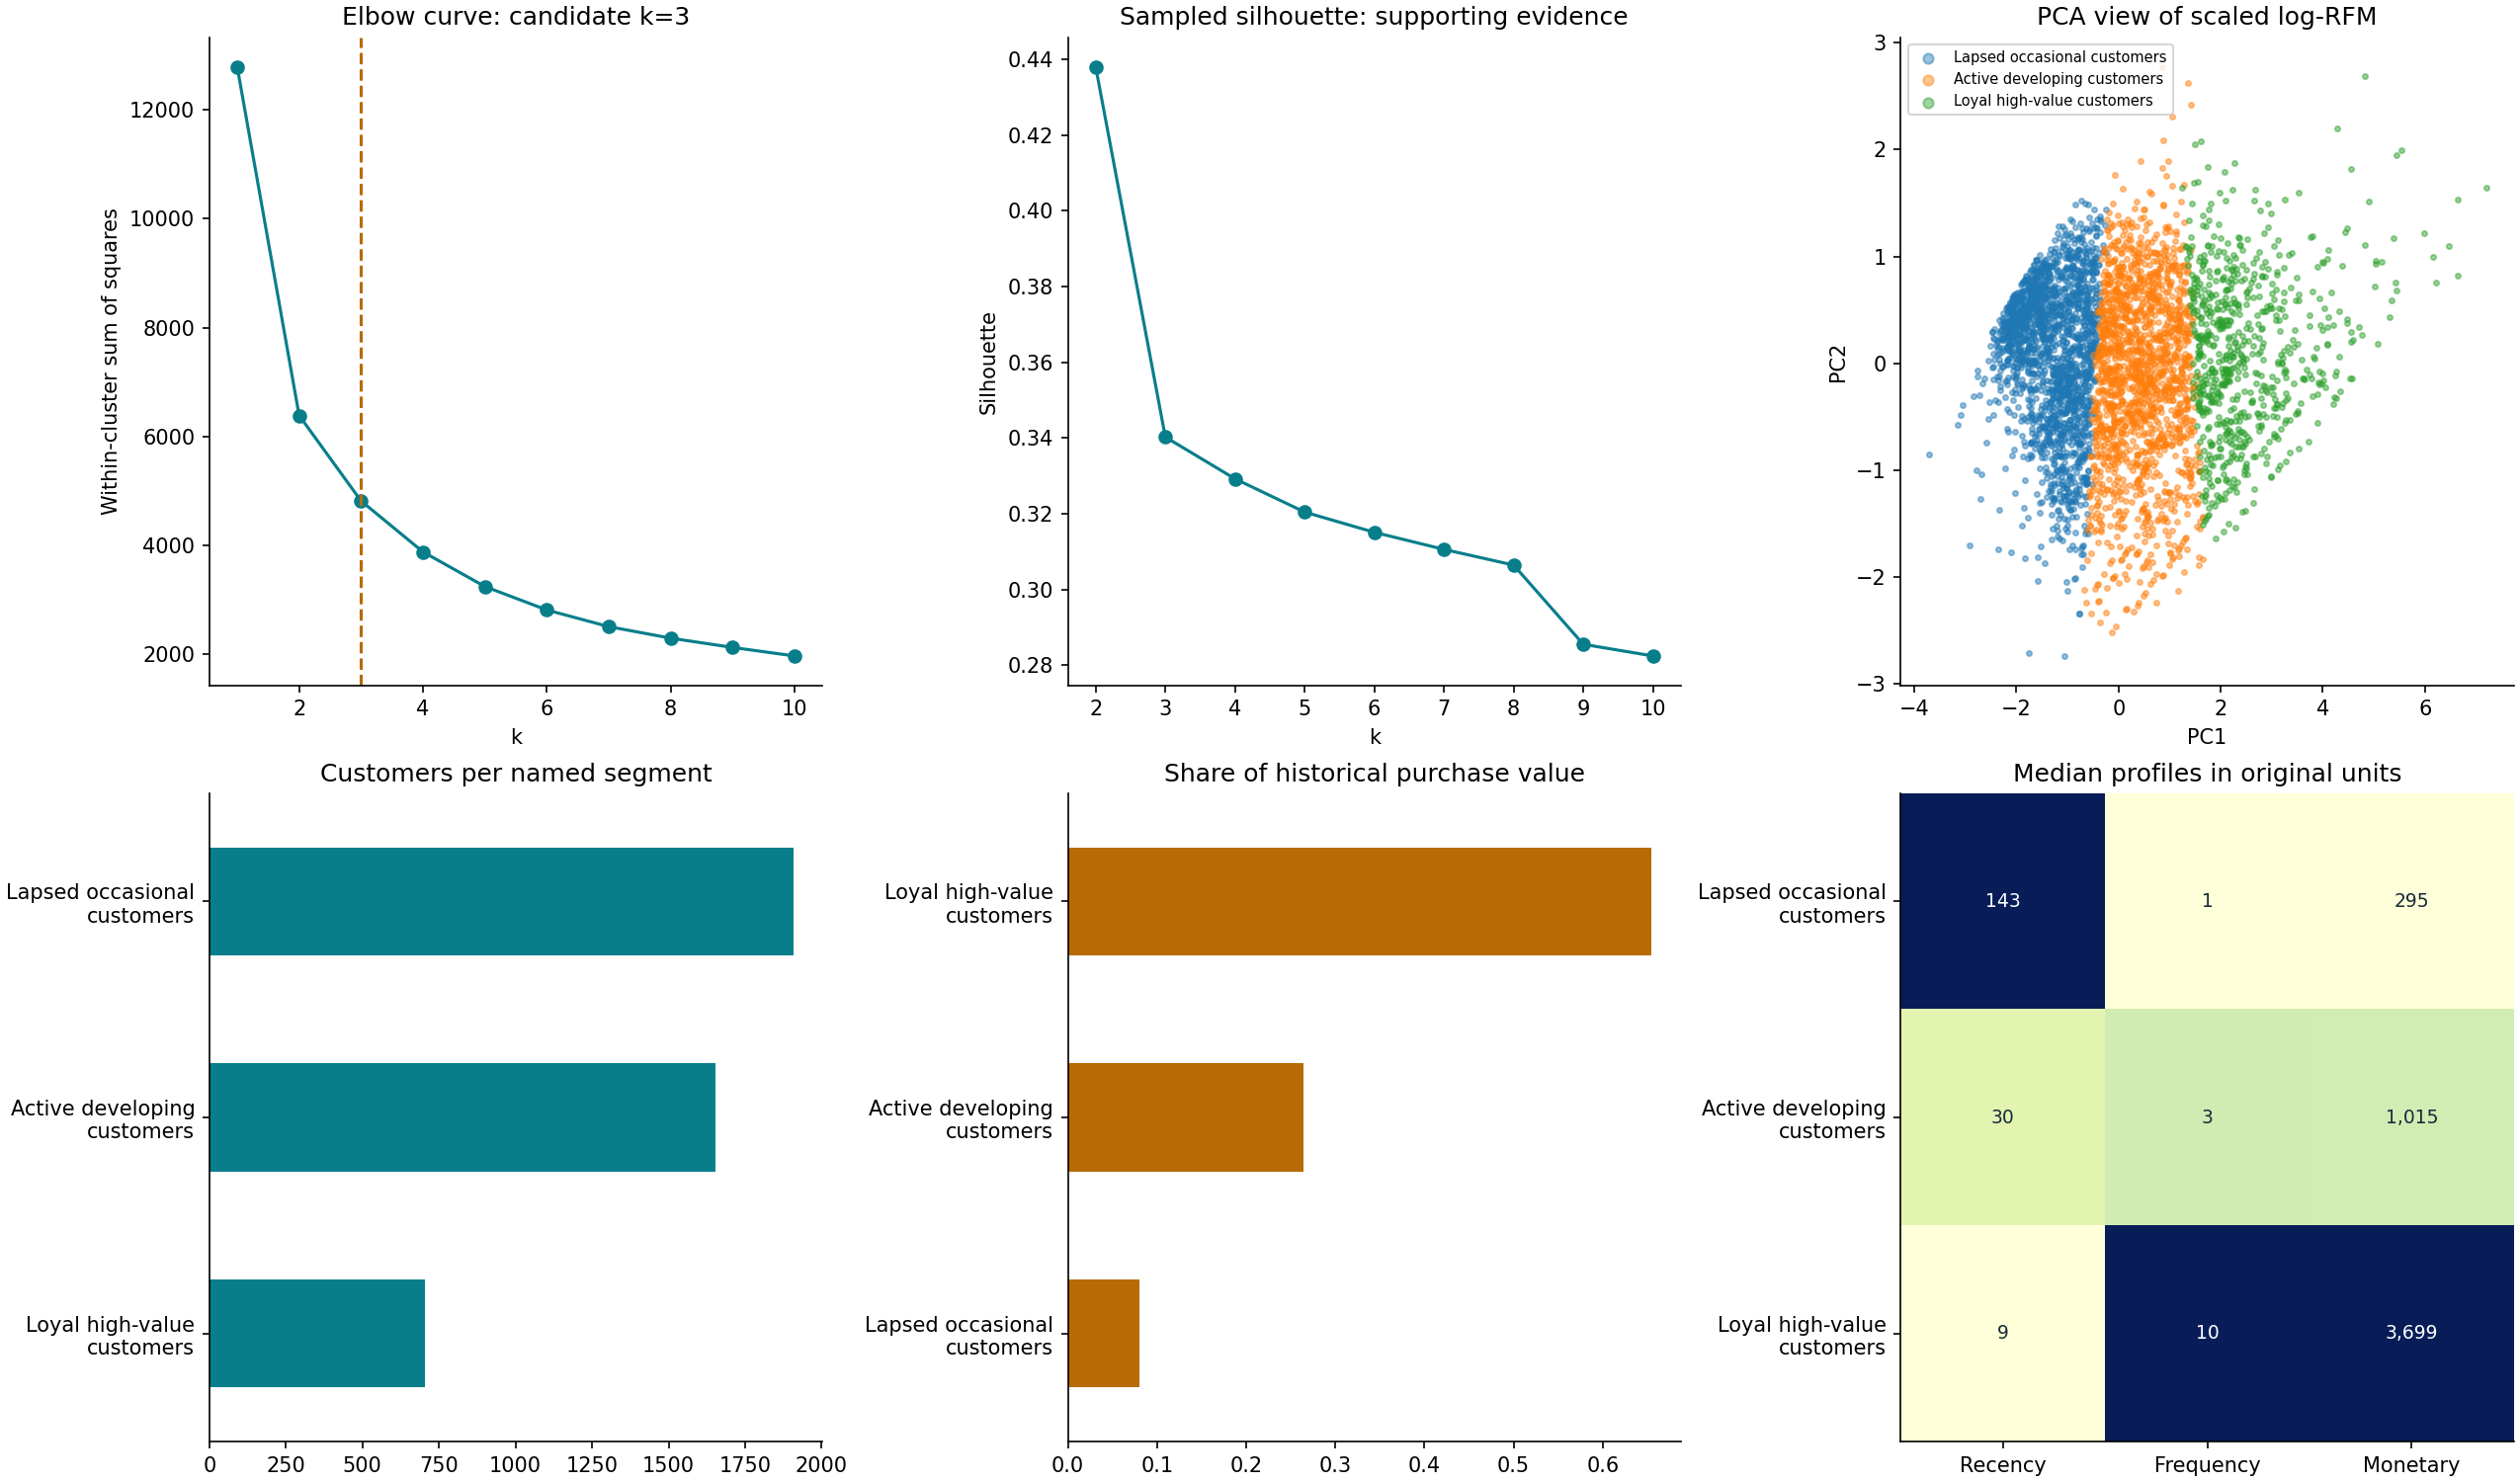

,baseline_tier,Active developing customers,Lapsed occasional customers,Loyal high-value customers
0,Champions,250,0,625
1,Developing customers,356,362,1
2,High value at risk of lapsing,292,106,13
3,Lapsed low-activity customers,8,1227,0
4,Loyal repeat customers,582,35,64
5,Newly observed customers still exploring,166,177,0


In [6]:
profiles=pd.read_csv('outputs/segment_profiles.csv')
customers=pd.read_csv('outputs/customer_segments.csv',dtype={'CustomerID':'string'})
display(profiles[['segment','customers','customer_share','value_share','Recency_median','Frequency_median','Monetary_median','average_order_value_median','unique_products_median','repeat_buyer_share']])
display(Image(filename='outputs/segmentation_evidence.png'))
display(pd.read_csv('outputs/baseline_vs_clusters.csv'))

## 7. Translate groups into actions
VIP recognition and relevant cross-sell for loyal customers; nurture repeat purchasing for active developing customers; low-cost reactivation tests for lapsed customers. Preserve manual high-value-at-risk and newly observed tiers as campaign overlays—broad cluster medians can hide valuable exceptions.

Group-level campaigns are hypotheses, not proof that members want a particular offer. Check contact eligibility and suppress duplicates. Historical purchase value is not expected incremental value.

In [7]:
display(pd.read_csv('outputs/campaign_playbook.csv'))
display(customers.groupby(['segment','recommended_campaign']).size().to_frame('customers'))
display(customers[['CustomerID','segment','baseline_tier','RFM_code','recommended_campaign']].head(15))

,segment,customers,campaign,message_or_offer,primary_kpi,guardrail
0,Lapsed occasional customers,1907,Low-cost reactivation pilot,Test a small email group and suppress nonrespo...,Incremental reactivation net of contact cost,Do not spend heavily on low-response customers...
1,Active developing customers,1654,Nurture repeat purchasing,Relevant product follow-up; use observed baske...,Incremental 30-day repeat-purchase rate,Interest is not inferred beyond observed purch...
2,Loyal high-value customers,703,VIP recognition and cross-sell,Early access or relevant bundles; test non-dis...,Incremental contribution per eligible customer,Do not subsidize purchases that would occur an...


customers
segment                     recommended_campaign                               
Active developing customers Nurture repeat purchasing                      1196
                            Personalized win-back (RFM overlay)             292
                            Second-purchase onboarding (RFM overlay)        166
Lapsed occasional customers Low-cost reactivation pilot                    1624
                            Personalized win-back (RFM overlay)             106
                            Second-purchase onboarding (RFM overlay)        177
Loyal high-value customers  Personalized win-back (RFM overlay)              13
                            VIP recognition and cross-sell                  690

,CustomerID,segment,baseline_tier,RFM_code,recommended_campaign
0,12346,Active developing customers,High value at risk of lapsing,115,Personalized win-back (RFM overlay)
1,12347,Loyal high-value customers,Champions,555,VIP recognition and cross-sell
2,12348,Active developing customers,High value at risk of lapsing,244,Personalized win-back (RFM overlay)
3,12349,Active developing customers,Newly observed customers still exploring,414,Second-purchase onboarding (RFM overlay)
4,12350,Lapsed occasional customers,Lapsed low-activity customers,112,Low-cost reactivation pilot
5,12352,Loyal high-value customers,Loyal repeat customers,355,VIP recognition and cross-sell
6,12353,Lapsed occasional customers,Lapsed low-activity customers,111,Low-cost reactivation pilot
7,12354,Lapsed occasional customers,High value at risk of lapsing,114,Personalized win-back (RFM overlay)
8,12355,Lapsed occasional customers,Lapsed low-activity customers,112,Low-cost reactivation pilot
9,12356,Active developing customers,Loyal repeat customers,435,Nurture repeat purchasing


## 8. Behavioral lenses and missing-data expansion
Existing transaction-derived lenses: average order value, basket units, unique products, repeat purchase, first observed age, top purchased SKU and modal country. They profile the RFM clusters; they are not additional model features. Top SKU does not establish interest, and country is not household composition.

With authorized broader data, evaluate opt-in engagement, category taxonomy, lifecycle and household lenses. Avoid inferring demographics or household wealth from baskets, particularly where wholesalers are present. Test usefulness and fairness before expanding clustering.

In [8]:
display(customers.groupby('segment')[['average_order_value','units_per_order','unique_products','first_observed_age_days']].median())
display(customers.groupby(['segment','country']).size().groupby(level=0).nlargest(3).to_frame('customers'))

,average_order_value,units_per_order,unique_products,first_observed_age_days
segment,,,,
Active developing customers,317.210000,182.583333,51.0,236.5
Lapsed occasional customers,221.440000,126.500000,18.0,190.0
Loyal high-value customers,371.117222,217.285714,116.0,327.0


customers
segment                     segment                     country                  
Active developing customers Active developing customers United Kingdom       1483
                                                        Germany                39
                                                        France                 32
Lapsed occasional customers Lapsed occasional customers United Kingdom       1750
                                                        France                 31
                                                        Germany                31
Loyal high-value customers  Loyal high-value customers  United Kingdom        621
                                                        Germany                23
                                                        France                 22

## 9. Reusable assignment and audience export
New customer RFM must use the same units, 365-day window and definitions. The frozen pipeline assigns names; it does not retrain or prove compatibility with another business. Distance to center is not a probability. Without first-observed history, a baseline “new” tier is not assigned.

In [9]:
from src.predict import assign_segments
example=pd.read_csv('data/example_rfm.csv',dtype={'CustomerID':'string'})
display(assign_segments(example))
print('Full audience export: outputs/customer_segments.csv')

Full audience export: outputs/customer_segments.csv


,CustomerID,Recency,Frequency,Monetary,segment,cluster_id,distance_to_center,R_score,F_score,M_score,RFM_code,baseline_tier
0,12346,326,1,77183.60,Active developing customers,1,4.084474,1,1,5,115,High value at risk of lapsing
1,12347,3,6,3598.21,Loyal high-value customers,2,1.076311,5,5,5,555,Champions
2,12348,76,4,1797.24,Active developing customers,1,0.918649,2,4,4,244,High value at risk of lapsing
3,12349,19,1,1757.55,Active developing customers,1,1.221095,4,1,4,414,Developing customers
4,12350,311,1,334.40,Lapsed occasional customers,0,0.798911,1,1,2,112,Lapsed low-activity customers
5,12352,37,8,2506.04,Loyal high-value customers,2,1.182702,3,5,5,355,Loyal repeat customers
6,12353,205,1,89.00,Lapsed occasional customers,0,1.012974,1,1,1,111,Lapsed low-activity customers
7,12354,233,1,1079.40,Lapsed occasional customers,0,1.229602,1,1,4,114,High value at risk of lapsing
8,12355,215,1,459.40,Lapsed occasional customers,0,0.655319,1,1,2,112,Lapsed low-activity customers
9,12356,23,3,2811.43,Active developing customers,1,0.833434,4,3,5,435,Loyal repeat customers


## 10. Validate campaigns rather than claim conversion gains
Within each named segment, randomize appropriately consented customers to a targeted campaign or control. Prespecify conversion window, contribution metric, contact/offer costs, minimum detectable effect and sample size. Account for multiple segment tests. Measure incremental conversions and net contribution, not just opens or clicks.

The dataset has no campaign exposure, control assignment, permissions, household attributes or observed marketing conversion uplift. No such fields are fabricated. A current campaign needs current data, a fresh snapshot and drift review; this historic analysis is descriptive.

See README, DATA_DICTIONARY, SEGMENT_PLAYBOOK, MODEL_CARD, REQUIREMENTS_AUDIT and GITHUB_GUIDE. The local dashboard uses native light/dark theming and supports filters, audience export and RFM CSV assignment.